# Indian Petrol & Diesel Price Trend Analysis
### Exploratory Data Analysis and Visualization using Python

**College:** Chaitanya Bharathi Institute of Technology (CBIT), Hyderabad  
**Course:** Exploratory Data Analysis and Visualization using Python (EDAV)  
**Student:** Charan Tej Reddy Reddygari  
**Roll Number:** 160125737122  
**Repository:** `EDAV-COURSE-END-PROJECT`

## 1. Project overview
This project explores selected reported petrol and diesel retail-price observations in India. It studies long-run point-in-time snapshots for Delhi and compares a single 10 August 2026 snapshot across four metro cities (Delhi, Mumbai, Chennai and Kolkata). The workflow uses NumPy, Pandas, Matplotlib and Seaborn.

> **Important data limitation:** The included CSV has 58 observations and is a small, source-attributed *curated snapshot dataset*, not the complete daily PPAC dataset. Historical Delhi values are point-in-time figures transcribed from a secondary year-wise table; they are not annual averages. The four-city comparison is one date only. Do not interpret gaps between snapshots as daily prices or claim that this sample describes every Indian state.

## 2. Objectives
- Inspect and clean a structured real-world dataset.
- Analyze petrol and diesel price levels and differences.
- Compare reported snapshots over time and across metro cities.
- Demonstrate NumPy indexing, broadcasting, arithmetic, transposition, matrix operations and random-array generation.
- Demonstrate Pandas grouping, merging, reshaping, hierarchical indexing, missing-value handling and time-series resampling.
- Communicate findings with line, bar, histogram, scatter and categorical visualizations.

## 3. Dataset and sources

**College:** Chaitanya Bharathi Institute of Technology (CBIT), Hyderabad. Official spelling verified at [cbit.ac.in](https://www.cbit.ac.in/about_post/about/).
The file `fuel_prices.csv` contains 58 rows and 9 columns: date, city, state/UT, fuel type, price in INR per litre, observation kind, source name, source URL and notes. It includes 25 paired historical Delhi snapshots and 8 observations (two fuel types for each of four cities) for 10 August 2026.

- Historical Delhi snapshot table: [MyCarHelpline — Petrol & Diesel Price in India Year Wise](https://www.mycarhelpline.com/index.php?Itemid=91&id=808&option=com_easyblog&view=entry). This is a secondary source; the table reports prices for selected months.
- Official context / full source dataset: [Dataful — Daily Retail Selling Price of Petrol and Diesel in Metro Cities for IOC](https://dataful.in/datasets/329/), attributed to the [Petroleum Planning & Analysis Cell (PPAC)](https://ppac.gov.in/). Dataful lists August 2026 as the dataset page update month; its preview shows `10-08-2026`, interpreted here as 10 August 2026. The source page describes 27,074 rows covering 2002–2026, with 2002–2017 records available only for Delhi and daily price changes applicable from 16 June 2017. The included project CSV is a small sample, not that full source dataset.

## 4. Tools
Python, Jupyter Notebook, NumPy, Pandas, Matplotlib, Seaborn.

## 5. Analysis workflow
1. Load and inspect the data.
2. Clean column types and check missing/duplicate records.
3. Add derived fields such as year, month, and petrol–diesel gap.
4. Use NumPy for array operations.
5. Use Pandas grouping, merge, pivot and MultiIndex.
6. Analyze time-indexed observations and demonstrate resampling.
7. Build complementary visualizations.
8. Summarize findings from calculated results, keeping limitations visible.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
DATA_PATH = Path("fuel_prices.csv")
df_raw = pd.read_csv(DATA_PATH)
print("Shape:", df_raw.shape)
display(df_raw.head())
display(df_raw.info())

Shape: (58, 9)


,date,city,state_or_ut,fuel_type,price_inr_per_litre,observation_kind,source_name,source_url,notes
0,2003-04-01,Delhi,Delhi,Diesel,22.12,historical_snapshot,MyCarHelpline year-wise petrol and diesel pric...,https://www.mycarhelpline.com/index.php?Itemid...,Reported point-in-time snapshot for the stated...
1,2003-04-01,Delhi,Delhi,Petrol,33.49,historical_snapshot,MyCarHelpline year-wise petrol and diesel pric...,https://www.mycarhelpline.com/index.php?Itemid...,Reported point-in-time snapshot for the stated...
2,2004-06-01,Delhi,Delhi,Diesel,22.74,historical_snapshot,MyCarHelpline year-wise petrol and diesel pric...,https://www.mycarhelpline.com/index.php?Itemid...,Reported point-in-time snapshot for the stated...
3,2004-06-01,Delhi,Delhi,Petrol,35.71,historical_snapshot,MyCarHelpline year-wise petrol and diesel pric...,https://www.mycarhelpline.com/index.php?Itemid...,Reported point-in-time snapshot for the stated...
4,2005-04-01,Delhi,Delhi,Diesel,28.22,historical_snapshot,MyCarHelpline year-wise petrol and diesel pric...,https://www.mycarhelpline.com/index.php?Itemid...,Reported point-in-time snapshot for the stated...


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58 entries, 0 to 57
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   date                 58 non-null     object 
 1   city                 58 non-null     object 
 2   state_or_ut          58 non-null     object 
 3   fuel_type            58 non-null     object 
 4   price_inr_per_litre  58 non-null     float64
 5   observation_kind     58 non-null     object 
 6   source_name          58 non-null     object 
 7   source_url           58 non-null     object 
 8   notes                58 non-null     object 
dtypes: float64(1), object(8)
memory usage: 4.2+ KB


None

## 6. Data quality inspection and cleaning
The cleaning steps standardize date and numeric types, trim text fields, identify missing values, and check duplicate observation keys. Missing prices are not silently invented or interpolated. Because this curated file combines two source types, `observation_kind` and `source_name` are retained throughout the analysis.

In [2]:
df = df_raw.copy()
df.columns = df.columns.str.strip().str.lower()
for col in ["city", "state_or_ut", "fuel_type", "observation_kind", "source_name", "source_url", "notes"]:
    df[col] = df[col].astype("string").str.strip()
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["price_inr_per_litre"] = pd.to_numeric(df["price_inr_per_litre"], errors="coerce")
df["fuel_type"] = df["fuel_type"].str.title()

print("Missing values by column:")
display(df.isna().sum().to_frame("missing_count"))
key_cols = ["date", "city", "fuel_type", "observation_kind"]
print("Duplicate observation keys:", int(df.duplicated(key_cols).sum()))
df = df.drop_duplicates(subset=key_cols, keep="first")
df = df.dropna(subset=["date", "city", "fuel_type", "price_inr_per_litre"])
df = df[df["price_inr_per_litre"] > 0].copy()
df = df.sort_values(["date", "city", "fuel_type"]).reset_index(drop=True)
print("Cleaned shape:", df.shape)
display(df.head())

Missing values by column:


,missing_count
date,0
city,0
state_or_ut,0
fuel_type,0
price_inr_per_litre,0
observation_kind,0
source_name,0
source_url,0
notes,0


Duplicate observation keys: 0
Cleaned shape: (58, 9)


,date,city,state_or_ut,fuel_type,price_inr_per_litre,observation_kind,source_name,source_url,notes
0,2003-04-01,Delhi,Delhi,Diesel,22.12,historical_snapshot,MyCarHelpline year-wise petrol and diesel pric...,https://www.mycarhelpline.com/index.php?Itemid...,Reported point-in-time snapshot for the stated...
1,2003-04-01,Delhi,Delhi,Petrol,33.49,historical_snapshot,MyCarHelpline year-wise petrol and diesel pric...,https://www.mycarhelpline.com/index.php?Itemid...,Reported point-in-time snapshot for the stated...
2,2004-06-01,Delhi,Delhi,Diesel,22.74,historical_snapshot,MyCarHelpline year-wise petrol and diesel pric...,https://www.mycarhelpline.com/index.php?Itemid...,Reported point-in-time snapshot for the stated...
3,2004-06-01,Delhi,Delhi,Petrol,35.71,historical_snapshot,MyCarHelpline year-wise petrol and diesel pric...,https://www.mycarhelpline.com/index.php?Itemid...,Reported point-in-time snapshot for the stated...
4,2005-04-01,Delhi,Delhi,Diesel,28.22,historical_snapshot,MyCarHelpline year-wise petrol and diesel pric...,https://www.mycarhelpline.com/index.php?Itemid...,Reported point-in-time snapshot for the stated...


## 7. Feature engineering and descriptive statistics
Derived features are calculated from the observed rows. The petrol–diesel gap is computed only when both fuels are available for the same date and city.

In [3]:
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["month_name"] = df["date"].dt.strftime("%b")
df["year_month"] = df["date"].dt.to_period("M").astype(str)
df["price_band"] = pd.cut(df["price_inr_per_litre"], bins=[0, 50, 75, 100, 125, np.inf],
                           labels=["≤ ₹50", "₹50–75", "₹75–100", "₹100–125", "> ₹125"])

summary = df.groupby(["city", "fuel_type"], observed=True)["price_inr_per_litre"].agg(
    observations="count", minimum="min", mean="mean", median="median", maximum="max", std_dev="std"
).round(2)
display(summary)

wide = df.pivot_table(index=["date", "city", "observation_kind"], columns="fuel_type",
                      values="price_inr_per_litre", aggfunc="mean").reset_index()
if {"Petrol", "Diesel"}.issubset(wide.columns):
    wide["petrol_minus_diesel"] = wide["Petrol"] - wide["Diesel"]
display(wide.head(10))

observations  minimum    mean  median  maximum  std_dev
city    fuel_type                                                         
Chennai Diesel                1    99.55   99.55   99.55    99.55      NaN
        Petrol                1   107.77  107.77  107.77   107.77      NaN
Delhi   Diesel               26    22.12   56.64   51.52    96.67    25.28
        Petrol               26    33.49   67.64   64.34   105.41    22.79
Kolkata Diesel                1    99.82   99.82   99.82    99.82      NaN
        Petrol                1   113.51  113.51  113.51   113.51      NaN
Mumbai  Diesel                1    97.83   97.83   97.83    97.83      NaN
        Petrol                1   111.21  111.21  111.21   111.21      NaN

fuel_type,date,city,observation_kind,Diesel,Petrol,petrol_minus_diesel
0,2003-04-01,Delhi,historical_snapshot,22.12,33.49,11.37
1,2004-06-01,Delhi,historical_snapshot,22.74,35.71,12.97
2,2005-04-01,Delhi,historical_snapshot,28.22,37.99,9.77
3,2006-04-01,Delhi,historical_snapshot,30.45,43.50,13.05
4,2007-04-01,Delhi,historical_snapshot,30.25,43.00,12.75
5,2008-04-01,Delhi,historical_snapshot,31.76,45.50,13.74
6,2009-04-01,Delhi,historical_snapshot,30.86,44.70,13.84
7,2010-04-01,Delhi,historical_snapshot,38.10,48.00,9.90
8,2011-04-01,Delhi,historical_snapshot,37.75,58.50,20.75
9,2012-04-01,Delhi,historical_snapshot,40.91,65.60,24.69


## 8. NumPy demonstrations (Course Outcome 1)
These small examples demonstrate NumPy operations separately from the observed price data. The random array below is only a reproducible programming demonstration; it is **not fuel-price data** and is never merged into the analysis.

In [4]:
# Array creation and indexing
prices = df["price_inr_per_litre"].to_numpy(dtype=float)
print("First five observed prices:", prices[:5])
print("Price at index 0:", prices[0])
print("Shape:", prices.shape, " | Mean:", round(float(np.mean(prices)), 2))

# Arithmetic and broadcasting
sample = np.array([10.0, 20.0, 30.0])
adjustment = np.array([1.0])
print("Array + scalar-like broadcast:", sample + adjustment)
print("Elementwise multiplication:", sample * np.array([2.0, 2.0, 2.0]))

# Matrix operations and transpose
matrix = np.array([[1, 2, 3], [4, 5, 6]], dtype=float)
print("Matrix:\n", matrix)
print("Transpose:\n", matrix.T)
print("Matrix product with transpose:\n", matrix @ matrix.T)

# Reproducible random-number generation (demonstration only)
rng = np.random.default_rng(42)
random_demo = rng.integers(1, 10, size=(2, 3))
print("Random demo array (not observed data):\n", random_demo)

First five observed prices: [22.12 33.49 22.74 35.71 28.22]
Price at index 0: 22.12
Shape: (58,)  | Mean: 66.57
Array + scalar-like broadcast: [11. 21. 31.]
Elementwise multiplication: [20. 40. 60.]
Matrix:
 [[1. 2. 3.]
 [4. 5. 6.]]
Transpose:
 [[1. 4.]
 [2. 5.]
 [3. 6.]]
Matrix product with transpose:
 [[14. 32.]
 [32. 77.]]
Random demo array (not observed data):
 [[1 7 6]
 [4 4 8]]


## 9. Pandas merge, grouping, reshaping and hierarchical indexing (Course Outcome 2 & 3)

In [5]:
# A small city dimension table; merge adds descriptive geography to each observation.
city_info = pd.DataFrame({
    "city": ["Delhi", "Mumbai", "Chennai", "Kolkata"],
    "region_group": ["North", "West", "South", "East"]
})
merged = df.merge(city_info, on="city", how="left", validate="many_to_one")
print("Unmatched cities after merge:", int(merged["region_group"].isna().sum()))

# Group operations: mean and range by city and fuel.
grouped = merged.groupby(["city", "fuel_type"], observed=True).agg(
    mean_price=("price_inr_per_litre", "mean"),
    min_price=("price_inr_per_litre", "min"),
    max_price=("price_inr_per_litre", "max"),
    n=("price_inr_per_litre", "size")
).round(2)
display(grouped)

# Hierarchical (MultiIndex) indexing: date x city x fuel.
mi = merged.set_index(["date", "city", "fuel_type"]).sort_index()
display(mi.head(8))
print("Delhi petrol observations:")
try:
    display(mi.xs(("Delhi", "Petrol"), level=("city", "fuel_type"), drop_level=False).head())
except KeyError:
    print("No Delhi petrol rows found for the selected index keys.")

# Reshaping long -> wide and wide -> long.
pivot = merged.pivot_table(index=["date", "city"], columns="fuel_type", values="price_inr_per_litre", aggfunc="mean")
display(pivot.head())
long_again = pivot.reset_index().melt(id_vars=["date", "city"], var_name="fuel_type", value_name="price_inr_per_litre")
display(long_again.head())

Unmatched cities after merge: 0


mean_price  min_price  max_price   n
city    fuel_type                                      
Chennai Diesel          99.55      99.55      99.55   1
        Petrol         107.77     107.77     107.77   1
Delhi   Diesel          56.64      22.12      96.67  26
        Petrol          67.64      33.49     105.41  26
Kolkata Diesel          99.82      99.82      99.82   1
        Petrol         113.51     113.51     113.51   1
Mumbai  Diesel          97.83      97.83      97.83   1
        Petrol         111.21     111.21     111.21   1

state_or_ut  ...  region_group
date       city  fuel_type              ...              
2003-04-01 Delhi Diesel          Delhi  ...         North
                 Petrol          Delhi  ...         North
2004-06-01 Delhi Diesel          Delhi  ...         North
                 Petrol          Delhi  ...         North
2005-04-01 Delhi Diesel          Delhi  ...         North
                 Petrol          Delhi  ...         North
2006-04-01 Delhi Diesel          Delhi  ...         North
                 Petrol          Delhi  ...         North

[8 rows x 12 columns]

Delhi petrol observations:


,,,state_or_ut,price_inr_per_litre,observation_kind,source_name,source_url,notes,year,month,month_name,year_month,price_band,region_group
date,city,fuel_type,,,,,,,,,,,,
2003-04-01,Delhi,Petrol,Delhi,33.49,historical_snapshot,MyCarHelpline year-wise petrol and diesel pric...,https://www.mycarhelpline.com/index.php?Itemid...,Reported point-in-time snapshot for the stated...,2003,4,Apr,2003-04,≤ ₹50,North
2004-06-01,Delhi,Petrol,Delhi,35.71,historical_snapshot,MyCarHelpline year-wise petrol and diesel pric...,https://www.mycarhelpline.com/index.php?Itemid...,Reported point-in-time snapshot for the stated...,2004,6,Jun,2004-06,≤ ₹50,North
2005-04-01,Delhi,Petrol,Delhi,37.99,historical_snapshot,MyCarHelpline year-wise petrol and diesel pric...,https://www.mycarhelpline.com/index.php?Itemid...,Reported point-in-time snapshot for the stated...,2005,4,Apr,2005-04,≤ ₹50,North
2006-04-01,Delhi,Petrol,Delhi,43.50,historical_snapshot,MyCarHelpline year-wise petrol and diesel pric...,https://www.mycarhelpline.com/index.php?Itemid...,Reported point-in-time snapshot for the stated...,2006,4,Apr,2006-04,≤ ₹50,North
2007-04-01,Delhi,Petrol,Delhi,43.00,historical_snapshot,MyCarHelpline year-wise petrol and diesel pric...,https://www.mycarhelpline.com/index.php?Itemid...,Reported point-in-time snapshot for the stated...,2007,4,Apr,2007-04,≤ ₹50,North


,fuel_type,Diesel,Petrol
date,city,,
2003-04-01,Delhi,22.12,33.49
2004-06-01,Delhi,22.74,35.71
2005-04-01,Delhi,28.22,37.99
2006-04-01,Delhi,30.45,43.50
2007-04-01,Delhi,30.25,43.00


,date,city,fuel_type,price_inr_per_litre
0,2003-04-01,Delhi,Diesel,22.12
1,2004-06-01,Delhi,Diesel,22.74
2,2005-04-01,Delhi,Diesel,28.22
3,2006-04-01,Delhi,Diesel,30.45
4,2007-04-01,Delhi,Diesel,30.25


## 10. Time-series analysis and resampling
The source observations are irregular snapshots, not a complete daily series. Resampling below summarizes **available observations** into calendar years; it does not fill missing days or imply that each year's statistic is an annual average of all daily prices.

In [6]:
delhi = df[(df["city"].eq("Delhi")) & (df["observation_kind"].eq("historical_snapshot"))].copy().sort_values("date")
delhi_ts = delhi.set_index("date")
annual_observed = delhi_ts.groupby("fuel_type")["price_inr_per_litre"].resample("YE").mean().dropna().rename("mean_of_available_snapshots").reset_index()
display(annual_observed.head(12))

# Time-based selection: show all recorded snapshots from 2020 onward.
display(delhi_ts.loc["2020-01-01":, ["fuel_type", "price_inr_per_litre", "observation_kind"]])

# Monthly resampling example, restricted to Delhi; months with no observation remain missing.
monthly_observed = delhi_ts.groupby("fuel_type")["price_inr_per_litre"].resample("MS").mean().dropna().reset_index()
display(monthly_observed.tail(12))

,fuel_type,date,mean_of_available_snapshots
0,Diesel,2003-12-31,22.12
1,Diesel,2004-12-31,22.74
2,Diesel,2005-12-31,28.22
3,Diesel,2006-12-31,30.45
4,Diesel,2007-12-31,30.25
5,Diesel,2008-12-31,31.76
6,Diesel,2009-12-31,30.86
7,Diesel,2010-12-31,38.10
8,Diesel,2011-12-31,37.75
9,Diesel,2012-12-31,40.91


,fuel_type,price_inr_per_litre,observation_kind
date,,,
2020-06-01,Petrol,79.76,historical_snapshot
2020-06-01,Diesel,79.88,historical_snapshot
2021-07-01,Diesel,89.36,historical_snapshot
2021-07-01,Petrol,99.86,historical_snapshot
2022-04-01,Diesel,96.67,historical_snapshot
2022-04-01,Petrol,105.41,historical_snapshot
2023-01-01,Diesel,89.62,historical_snapshot
2023-01-01,Petrol,96.72,historical_snapshot
2024-01-01,Diesel,89.62,historical_snapshot


,fuel_type,date,price_inr_per_litre
38,Petrol,2016-04-01,59.68
39,Petrol,2016-07-01,62.51
40,Petrol,2017-07-01,63.09
41,Petrol,2018-07-01,75.55
42,Petrol,2019-07-01,72.96
43,Petrol,2020-06-01,79.76
44,Petrol,2021-07-01,99.86
45,Petrol,2022-04-01,105.41
46,Petrol,2023-01-01,96.72
47,Petrol,2024-01-01,96.72


## 11. Visualizations (Course Outcome 4)
The plots answer different questions: time movement, cross-city comparison, price distribution, relationship between fuels, and category counts. The city comparison is a single-date comparison, whereas the long historical line chart is Delhi-only.

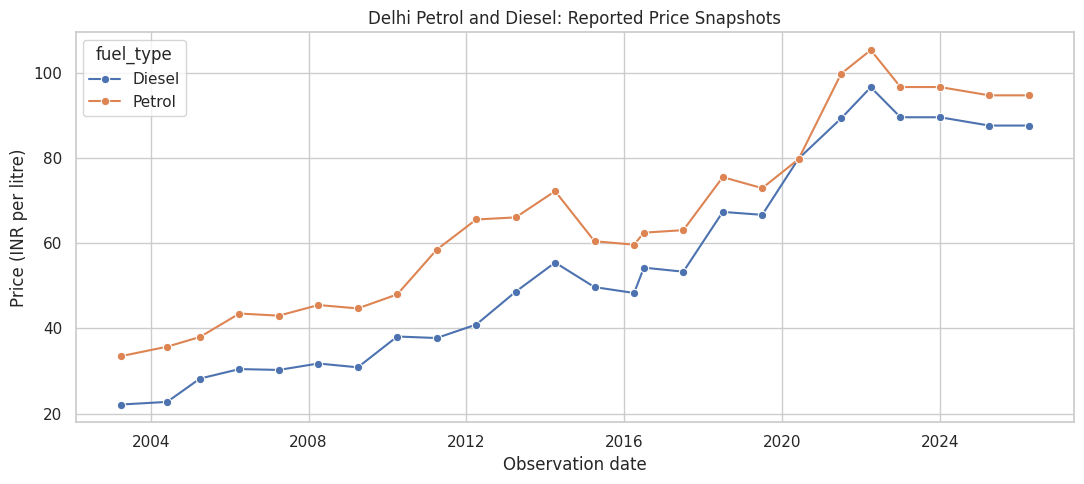

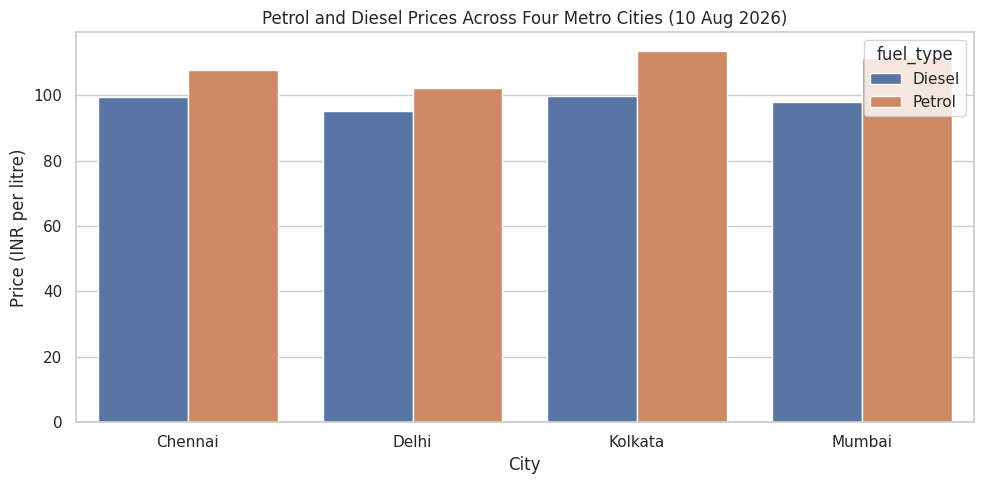

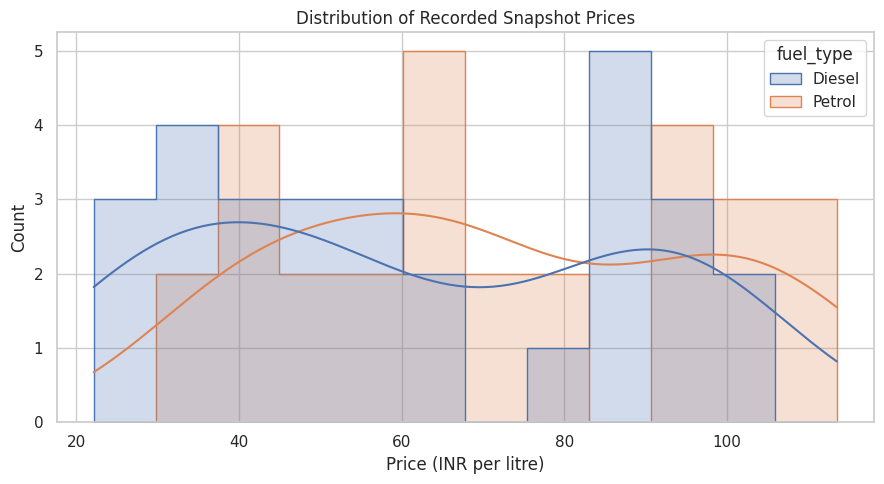

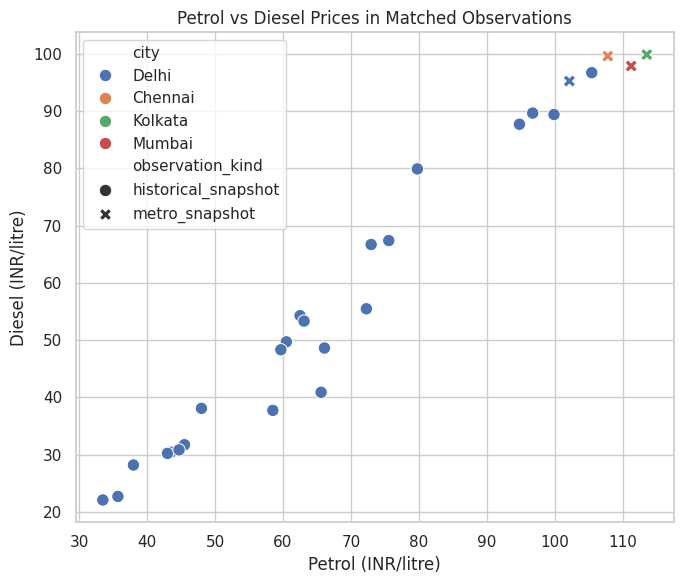

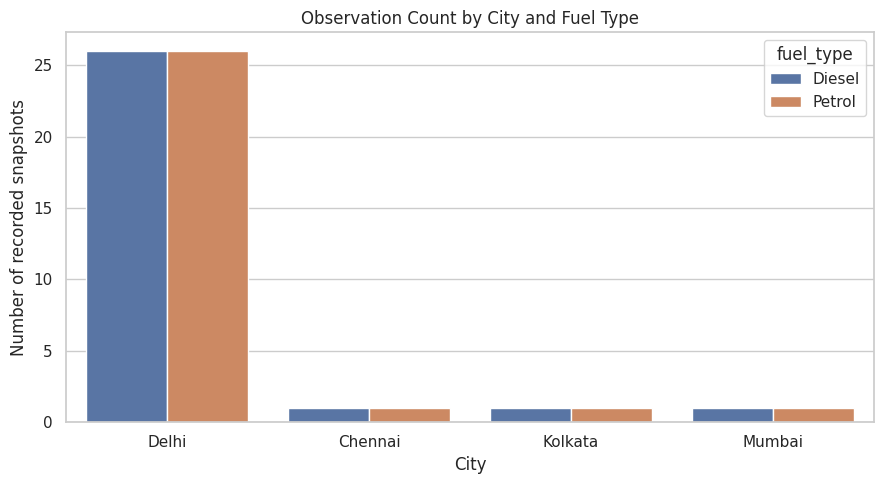

In [7]:
# 1. Line chart: historical Delhi snapshots
plt.figure(figsize=(11, 5))
sns.lineplot(data=delhi, x="date", y="price_inr_per_litre", hue="fuel_type", marker="o")
plt.title("Delhi Petrol and Diesel: Reported Price Snapshots")
plt.xlabel("Observation date"); plt.ylabel("Price (INR per litre)"); plt.tight_layout(); plt.show()

# 2. Bar chart: four-city snapshot on 10 Aug 2026
metro = df[df["observation_kind"].eq("metro_snapshot")]
plt.figure(figsize=(10, 5))
sns.barplot(data=metro, x="city", y="price_inr_per_litre", hue="fuel_type", errorbar=None)
plt.title("Petrol and Diesel Prices Across Four Metro Cities (10 Aug 2026)")
plt.xlabel("City"); plt.ylabel("Price (INR per litre)"); plt.tight_layout(); plt.show()

# 3. Histogram: distribution of observed prices (mixed observation scope; interpret cautiously)
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="price_inr_per_litre", hue="fuel_type", bins=12, kde=True, element="step")
plt.title("Distribution of Recorded Snapshot Prices")
plt.xlabel("Price (INR per litre)"); plt.tight_layout(); plt.show()

# 4. Scatter plot: petrol vs diesel where both values exist for same city/date
paired = df.pivot_table(index=["date", "city", "observation_kind"], columns="fuel_type", values="price_inr_per_litre", aggfunc="mean").dropna(subset=["Petrol", "Diesel"]).reset_index()
plt.figure(figsize=(7, 6))
sns.scatterplot(data=paired, x="Petrol", y="Diesel", hue="city", style="observation_kind", s=80)
plt.title("Petrol vs Diesel Prices in Matched Observations")
plt.xlabel("Petrol (INR/litre)"); plt.ylabel("Diesel (INR/litre)"); plt.tight_layout(); plt.show()

# 5. Categorical plot: number of recorded observations by city and fuel
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="city", hue="fuel_type")
plt.title("Observation Count by City and Fuel Type")
plt.xlabel("City"); plt.ylabel("Number of recorded snapshots"); plt.tight_layout(); plt.show()

## 12. Key findings (calculated from the included observations)
The following cells calculate the findings from the CSV so results remain tied to the data actually supplied. Interpret all findings alongside the sample limitations.

In [8]:
# Historical Delhi endpoints: first and last available observation for each fuel.
for fuel in ["Petrol", "Diesel"]:
    sub = delhi[delhi["fuel_type"].eq(fuel)].sort_values("date")
    if len(sub) >= 2:
        first, last = sub.iloc[0], sub.iloc[-1]
        change = last["price_inr_per_litre"] - first["price_inr_per_litre"]
        pct = change / first["price_inr_per_litre"] * 100
        print(f"Delhi {fuel}: {first['date'].date()} ₹{first['price_inr_per_litre']:.2f} -> "
              f"{last['date'].date()} ₹{last['price_inr_per_litre']:.2f}; "
              f"change ₹{change:.2f} ({pct:.1f}%).")

# Metro ranking for the common snapshot date.
metro_summary = metro.pivot(index="city", columns="fuel_type", values="price_inr_per_litre")
if not metro_summary.empty:
    print("Highest petrol snapshot:", metro_summary["Petrol"].idxmax(), f"₹{metro_summary['Petrol'].max():.2f}/L")
    print("Lowest petrol snapshot:", metro_summary["Petrol"].idxmin(), f"₹{metro_summary['Petrol'].min():.2f}/L")
    print("Highest diesel snapshot:", metro_summary["Diesel"].idxmax(), f"₹{metro_summary['Diesel'].max():.2f}/L")
    print("Lowest diesel snapshot:", metro_summary["Diesel"].idxmin(), f"₹{metro_summary['Diesel'].min():.2f}/L")
    metro_summary["petrol_minus_diesel"] = metro_summary["Petrol"] - metro_summary["Diesel"]
    display(metro_summary.round(2))

Delhi Petrol: 2003-04-01 ₹33.49 -> 2026-04-01 ₹94.77; change ₹61.28 (183.0%).
Delhi Diesel: 2003-04-01 ₹22.12 -> 2026-04-01 ₹87.67; change ₹65.55 (296.3%).
Highest petrol snapshot: Kolkata ₹113.51/L
Lowest petrol snapshot: Delhi ₹102.12/L
Highest diesel snapshot: Kolkata ₹99.82/L
Lowest diesel snapshot: Delhi ₹95.20/L


fuel_type,Diesel,Petrol,petrol_minus_diesel
city,,,
Chennai,99.55,107.77,8.22
Delhi,95.20,102.12,6.92
Kolkata,99.82,113.51,13.69
Mumbai,97.83,111.21,13.38


## 13. Conclusion
This EDA demonstrates a reproducible workflow for cleaning, deriving, grouping, reshaping, indexing and visualizing petrol/diesel price observations. The selected historical Delhi snapshots suggest that recorded prices increased substantially between the early 2000s and the latest historical snapshot included; the four-city snapshot also shows differences between metro cities on the same date. These are observations from the supplied sample, not causal explanations.

### Limitations and next steps
- The CSV is a curated sample, not the full daily PPAC dataset; historical values come from a secondary source.
- The observations are snapshots, so the notebook does not infer unobserved daily values or treat snapshots as annual averages.
- Metro comparisons cover four cities and one date, so they cannot represent all of India or city trends over time.
- For stronger inference, obtain the complete PPAC/Dataful CSV, preserve its original provenance, document the retrieval date, validate missing values, and rerun the notebook. Consider adding taxes or crude-oil prices only from reliable compatible sources.

## Course outcome coverage
| Course outcome | Where demonstrated |
|---|---|
| NumPy array creation, indexing, broadcasting, arithmetic, transpose, matrix operations, random generation | Section 8 |
| Pandas creation, cleaning, transforming, summarizing and analyzing structured data | Sections 5–7 |
| Missing values, categorization, merging, reshaping and hierarchical indexing | Sections 6–9 |
| Group operations, date conversion, time selection and resampling | Sections 7, 9–10 |
| Matplotlib/Seaborn line, bar, histogram, scatter and categorical charts | Section 11 |
| End-to-end domain-specific EDA | Sections 5–13 |

## References
1. Petroleum Planning & Analysis Cell (PPAC), Ministry of Petroleum & Natural Gas, Government of India: https://ppac.gov.in/
2. Dataful, *Daily Retail Selling Price of Petrol and Diesel in Metro Cities for IOC*: https://dataful.in/datasets/329/
3. MyCarHelpline, *Petrol & Diesel Price in India Year Wise*: https://www.mycarhelpline.com/index.php?Itemid=91&id=808&option=com_easyblog&view=entry